# TAHAPAN AWAL PEMODELAN

Langkah 1 — Pengumpulan data

> Mengunduh data BBCA dan memastikan periode serta kolomnya benar.

Langkah 2 — Eksplorasi data (EDA)

> Memeriksa distribusi return, nilai kosong, volatilitas, dan karakteristik data. Hasilnya membantu kita menentukan metode augmentasi yang masuk akal.

Langkah 3 — Menyiapkan fitur dan pembagian data

> Menentukan variabel prediktor dan memisahkan data secara kronologis agar informasi masa depan tidak bocor ke pelatihan.

Langkah 4 — Membangun model

> Setelah data dipahami, baru kita membangun data augmentation, ensemble, dan agen reinforcement learning.

In [ ]:
%pip install yfinance pandas matplotlib

# 1. Ambil Data

Jumlah observasi: 1199
Tanggal awal aktual: 2021-10-21
Tanggal akhir aktual: 2026-10-20

Data kosong:
 Price
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


Price,Open,High,Low,Close,Volume
Date,,,,,
2021-10-21,6381.087020,6423.627600,6253.465279,6296.005859,106120100
2021-10-22,6338.546551,6423.627712,6317.276260,6402.357422,96730700
2021-10-25,6296.005970,6402.357422,6296.005970,6402.357422,60329800
2021-10-26,6466.168293,6466.168293,6381.087131,6402.357422,70103000
2021-10-27,6444.897836,6444.897836,6317.276097,6338.546387,57067000


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-10-14,6000.0,6125.0,5950.0,6125.0,136303100
2026-10-15,6075.0,6125.0,6025.0,6075.0,134763200
2026-10-16,5825.0,5825.0,5175.0,5175.0,1241098200
2026-10-19,4820.0,4910.0,4820.0,4820.0,382924400
2026-10-20,4740.0,5200.0,4740.0,5200.0,1131013100


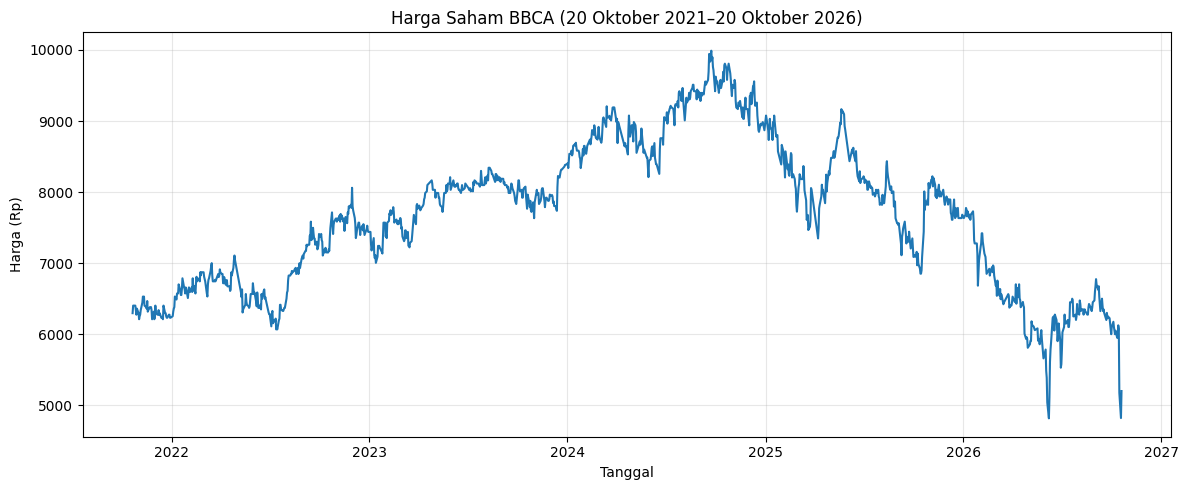

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

ticker = "BBCA.JK"
start_date = "2021-10-20"
end_date = "2026-10-21"

df = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=True,
    progress=False
)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

if df.empty:
    raise ValueError("Data kosong. Periksa koneksi atau kode saham.")

df = df[["Open", "High", "Low", "Close", "Volume"]].copy()
df.index = pd.to_datetime(df.index)
df.index.name = "Date"
df = df[~df.index.duplicated(keep="last")].sort_index()

# Pastikan tanggal sesuai periode yang diminta
df = df.loc[
    (df.index >= "2021-10-20") &
    (df.index <= "2026-10-20")
]

print("Jumlah observasi:", len(df))
print("Tanggal awal aktual:", df.index.min().date())
print("Tanggal akhir aktual:", df.index.max().date())
print("\nData kosong:\n", df.isna().sum())
display(df.head())
display(df.tail())

df.to_csv("data_BBCA_5tahun.csv")

plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Close"])
plt.title("Harga Saham BBCA (20 Oktober 2021–20 Oktober 2026)")
plt.xlabel("Tanggal")
plt.ylabel("Harga (Rp)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Eksplorasi Data

## 1. Periksa Kualitas Data



In [ ]:
# Pemeriksaan kualitas data
print("=== NILAI KOSONG ===")
print(data.isna().sum())

print("\n=== TANGGAL DUPLIKAT ===")
print("Jumlah:", data.index.duplicated().sum())

print("\n=== HARGA DAN VOLUME TIDAK VALID ===")
print("Harga Close <= 0:", (data["Close"] <= 0).sum())
print("Volume negatif:", (data["Volume"] < 0).sum())

print("\n=== STATISTIK DESKRIPTIF HARGA ===")
display(data[["Open", "High", "Low", "Close", "Volume"]].describe().T)


=== NILAI KOSONG ===
Price
Open      0
High      0
Low       0
Close     0
Volume    0
Return    1
dtype: int64

=== TANGGAL DUPLIKAT ===
Jumlah: 0

=== HARGA DAN VOLUME TIDAK VALID ===
Harga Close <= 0: 0
Volume negatif: 0

=== STATISTIK DESKRIPTIF HARGA ===


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Open,1199.0,7.650119e+03,1.030974e+03,4.740000e+03,6.727332e+03,7.749585e+03,8.330381e+03,9.944179e+03
High,1199.0,7.723163e+03,1.026567e+03,4.910000e+03,6.786650e+03,7.810229e+03,8.404843e+03,9.989796e+03
Low,1199.0,7.582176e+03,1.028150e+03,4.740000e+03,6.647929e+03,7.678927e+03,8.239674e+03,9.830141e+03
Close,1199.0,7.649567e+03,1.028635e+03,4.815876e+03,6.726603e+03,7.749585e+03,8.329235e+03,9.989796e+03
Volume,1199.0,1.115195e+08,1.094633e+08,1.065390e+07,6.131780e+07,8.529530e+07,1.227474e+08,1.432993e+09


## 2. Transformasi Log-Return

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan data tersedia
if "df" not in globals() or df.empty:
    raise ValueError("Data BBCA belum tersedia. Jalankan kode pengunduhan data terlebih dahulu.")

# Salin data agar data awal tetap tersimpan
data = df.copy()
data = data.sort_index()

# Pastikan kolom harga tersedia
if "Close" not in data.columns:
    raise ValueError("Kolom Close tidak ditemukan.")

# Hitung log return harian
data["Return"] = np.log(data["Close"] / data["Close"].shift(1))

# Data untuk analisis return
returns = data["Return"].dropna()

print("Jumlah data harga:", len(data))
print("Jumlah data return:", len(returns))
print("Periode:", returns.index.min().date(), "sampai", returns.index.max().date())
display(returns.head())

Jumlah data harga: 1199
Jumlah data return: 1198
Periode: 2021-10-22 sampai 2026-10-20


,Return
Date,
2021-10-22,0.016751
2021-10-25,0.000000
2021-10-26,0.000000
2021-10-27,-0.010017
2021-10-28,-0.010118


## 3. Analisis Karakteristik Return

,Nilai
count,1198.000000
mean,-0.000160
std,0.016828
min,-0.160343
25%,-0.009331
50%,0.000000
75%,0.008230
max,0.092659
Skewness,-0.632050
Kurtosis (excess),9.585274


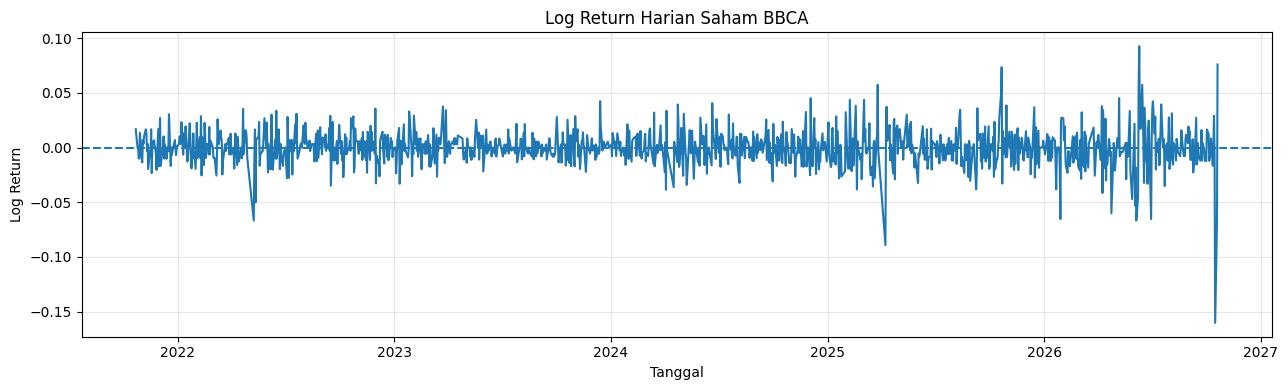

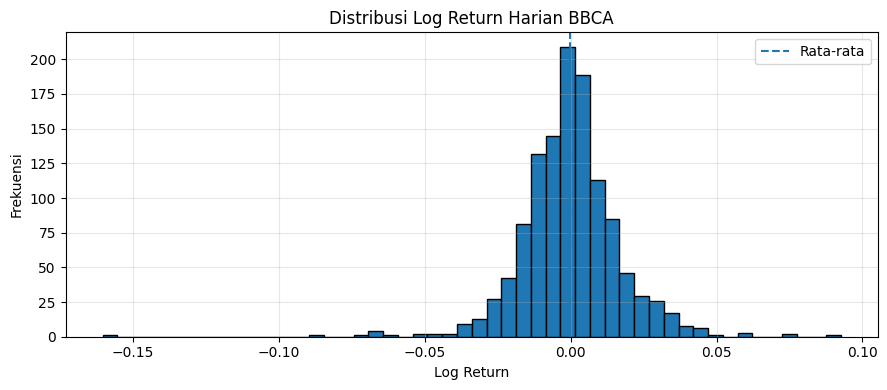

In [ ]:
# Statistik deskriptif return
stats = returns.describe().to_frame(name="Nilai")

stats.loc["Skewness"] = returns.skew()
stats.loc["Kurtosis (excess)"] = returns.kurtosis()
stats.loc["Jumlah return positif"] = (returns > 0).sum()
stats.loc["Jumlah return negatif"] = (returns < 0).sum()
stats.loc["Jumlah return nol"] = (returns == 0).sum()

display(stats)

# Grafik return harian
plt.figure(figsize=(13, 4))
plt.plot(returns.index, returns)
plt.axhline(0, linestyle="--")
plt.title("Log Return Harian Saham BBCA")
plt.xlabel("Tanggal")
plt.ylabel("Log Return")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Histogram return
plt.figure(figsize=(9, 4))
plt.hist(returns, bins=50, edgecolor="black")
plt.axvline(returns.mean(), linestyle="--", label="Rata-rata")
plt.title("Distribusi Log Return Harian BBCA")
plt.xlabel("Log Return")
plt.ylabel("Frekuensi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Periksa volatilitas dan pengelompokan fluktuasi

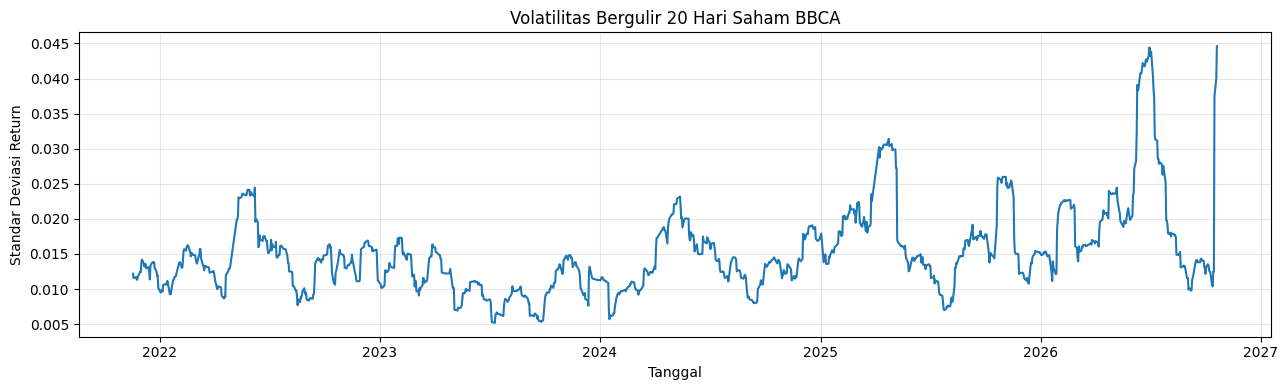

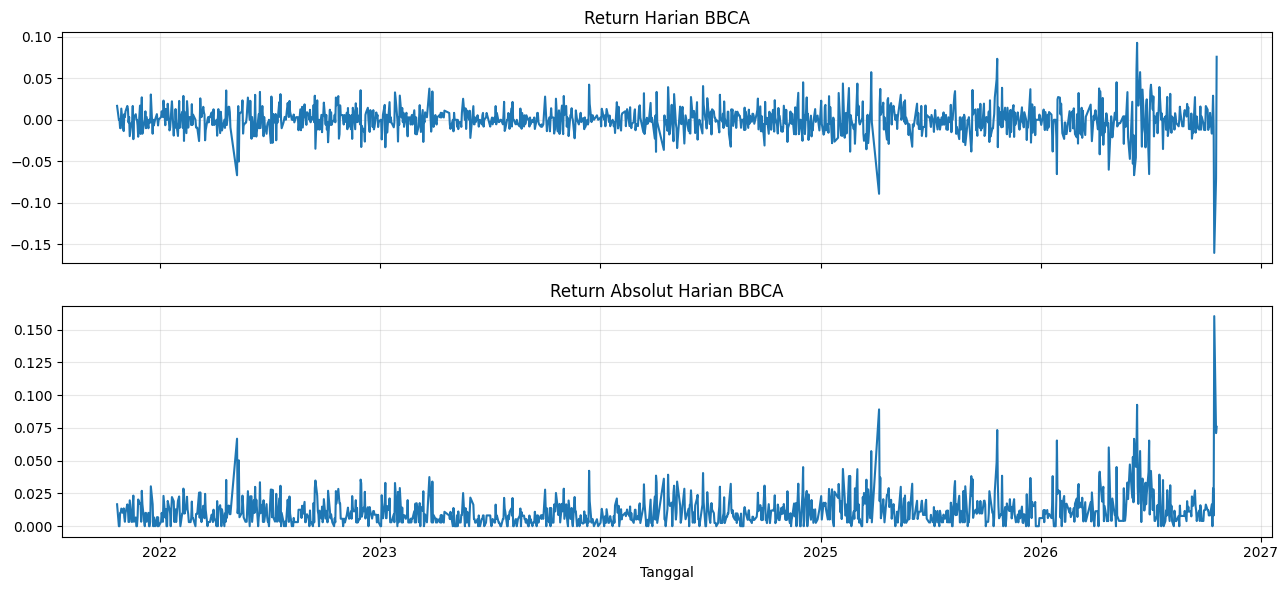

Autokorelasi return:


,Autokorelasi
Lag 1,-0.039924
Lag 2,-0.104574
Lag 3,-0.013231
Lag 4,-0.016204
Lag 5,-0.019963


Autokorelasi return absolut:


,Autokorelasi
Lag 1,0.236370
Lag 2,0.232763
Lag 3,0.146238
Lag 4,0.109390
Lag 5,0.099221


In [ ]:

# Volatilitas bergulir 20 hari
rolling_vol = returns.rolling(window=20).std()

plt.figure(figsize=(13, 4))
plt.plot(rolling_vol.index, rolling_vol)
plt.title("Volatilitas Bergulir 20 Hari Saham BBCA")
plt.xlabel("Tanggal")
plt.ylabel("Standar Deviasi Return")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Return dan return absolut
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

axes[0].plot(returns.index, returns)
axes[0].set_title("Return Harian BBCA")
axes[0].grid(True, alpha=0.3)

axes[1].plot(returns.index, returns.abs())
axes[1].set_title("Return Absolut Harian BBCA")
axes[1].set_xlabel("Tanggal")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Autokorelasi return dan return absolut
print("Autokorelasi return:")
display(pd.Series(
    {f"Lag {lag}": returns.autocorr(lag=lag) for lag in range(1, 6)},
    name="Autokorelasi"
).to_frame())

print("Autokorelasi return absolut:")
display(pd.Series(
    {f"Lag {lag}": returns.abs().autocorr(lag=lag) for lag in range(1, 6)},
    name="Autokorelasi"
).to_frame())

## 5. Identifikasi return ekstrem

Batas bawah: -0.05064465073720911
Batas atas: 0.05032535722105269
Jumlah return di luar batas: 15
Proporsi: 1.25%

Return ekstrem:


,Return
Date,
2022-05-09,-0.066798
2025-03-26,0.057331
2025-04-08,-0.089153
2025-10-21,0.073427
2026-01-28,-0.065428
2026-04-24,-0.060138
2026-06-03,-0.052876
2026-06-05,-0.066691
2026-06-09,0.060018


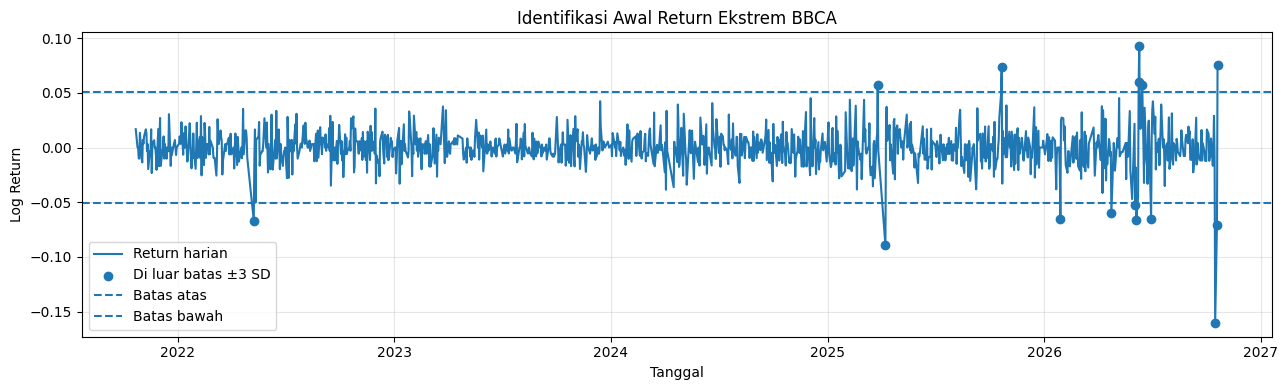

In [ ]:
# Batas ekstrem untuk eksplorasi awal
mu = returns.mean()
sigma = returns.std()

lower = mu - 3 * sigma
upper = mu + 3 * sigma

extreme_returns = returns[(returns < lower) | (returns > upper)]

print("Batas bawah:", lower)
print("Batas atas:", upper)
print("Jumlah return di luar batas:", len(extreme_returns))
print("Proporsi:", f"{len(extreme_returns) / len(returns) * 100:.2f}%")

print("\nReturn ekstrem:")
display(extreme_returns.to_frame(name="Return"))

# Tandai return ekstrem pada grafik
plt.figure(figsize=(13, 4))
plt.plot(returns.index, returns, label="Return harian")
plt.scatter(
    extreme_returns.index,
    extreme_returns.values,
    label="Di luar batas ±3 SD",
    zorder=3
)
plt.axhline(upper, linestyle="--", label="Batas atas")
plt.axhline(lower, linestyle="--", label="Batas bawah")
plt.title("Identifikasi Awal Return Ekstrem BBCA")
plt.xlabel("Tanggal")
plt.ylabel("Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

=== KARAKTERISTIK DISTRIBUSI RETURN ===
Rata-rata       : -0.000160
Standar deviasi : 0.016828
Skewness        : -0.6313
Excess kurtosis : 9.5403

=== UJI JARQUE-BERA ===
Statistik : 4622.8565
p-value   : 0.000000

=== AUTOKORELASI ===


,Lag,Return,Return absolut
0,1,-0.039924,0.236370
1,2,-0.104574,0.232763
2,3,-0.013231,0.146238
3,4,-0.016204,0.109390
4,5,-0.019963,0.099221
5,6,-0.051502,0.136051
6,7,-0.024894,0.109392
7,8,0.017784,0.117846
8,9,-0.036797,0.066829
9,10,-0.033100,0.107728


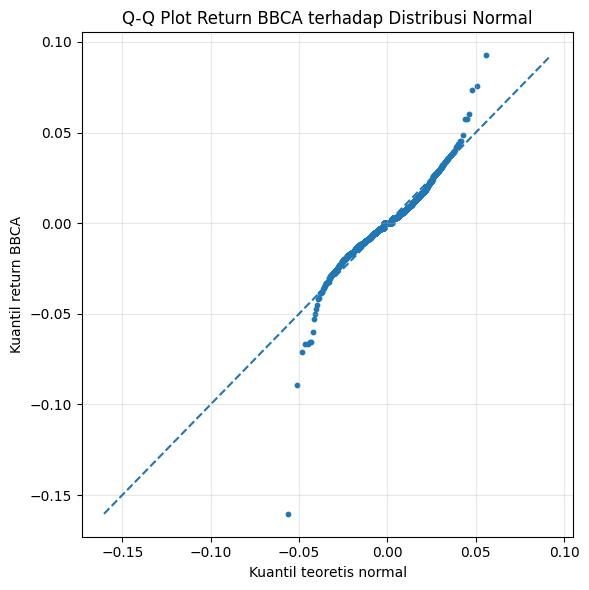

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 1. Statistik distribusi return
print("=== KARAKTERISTIK DISTRIBUSI RETURN ===")
print(f"Rata-rata       : {returns.mean():.6f}")
print(f"Standar deviasi : {returns.std():.6f}")
print(f"Skewness        : {stats.skew(returns):.4f}")
print(f"Excess kurtosis : {stats.kurtosis(returns):.4f}")

# 2. Uji normalitas Jarque-Bera
jb_stat, jb_pvalue = stats.jarque_bera(returns)

print("\n=== UJI JARQUE-BERA ===")
print(f"Statistik : {jb_stat:.4f}")
print(f"p-value   : {jb_pvalue:.6f}")

# 3. Autokorelasi return dan return absolut
print("\n=== AUTOKORELASI ===")
hasil_acf = pd.DataFrame({
    "Lag": range(1, 11),
    "Return": [returns.autocorr(lag=i) for i in range(1, 11)],
    "Return absolut": [
        returns.abs().autocorr(lag=i) for i in range(1, 11)
    ]
})
display(hasil_acf)

# 4. Bandingkan distribusi empiris dengan normal
x = np.sort(returns.to_numpy())
prob = (np.arange(1, len(x) + 1) - 0.5) / len(x)
normal_quantiles = stats.norm.ppf(prob, loc=returns.mean(),
                                  scale=returns.std())

plt.figure(figsize=(6, 6))
plt.scatter(normal_quantiles, x, s=10)
batas_min = min(normal_quantiles.min(), x.min())
batas_max = max(normal_quantiles.max(), x.max())
plt.plot([batas_min, batas_max],
         [batas_min, batas_max], linestyle="--")
plt.title("Q-Q Plot Return BBCA terhadap Distribusi Normal")
plt.xlabel("Kuantil teoretis normal")
plt.ylabel("Kuantil return BBCA")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


RINGKASAN EDA
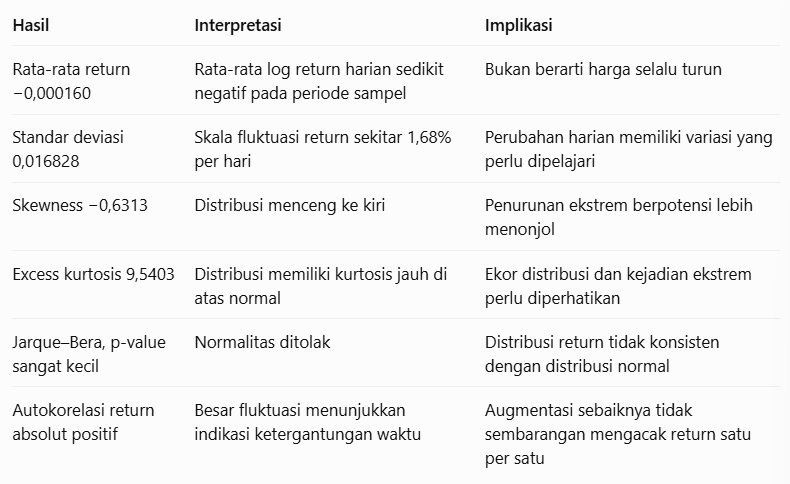

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# Uji Ljung-Box pada return kuadrat
lb_result = acorr_ljungbox(
    returns ** 2,
    lags=[5, 10, 20],
    return_df=True
)

print("=== UJI LJUNG-BOX PADA RETURN KUADRAT ===")
display(lb_result)

# Uji ARCH-LM pada return
arch_stat, arch_pvalue, _, _ = het_arch(returns, nlags=10)

print("=== UJI ARCH-LM ===")
print(f"Statistik LM : {arch_stat:.4f}")
print(f"p-value      : {arch_pvalue:.6g}")

=== UJI LJUNG-BOX PADA RETURN KUADRAT ===


,lb_stat,lb_pvalue
5,125.038443,2.685399e-25
10,132.973938,1.154324e-23
20,141.080564,3.156454e-20


=== UJI ARCH-LM ===
Statistik LM : 110.5069
p-value      : 4.21655e-19


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


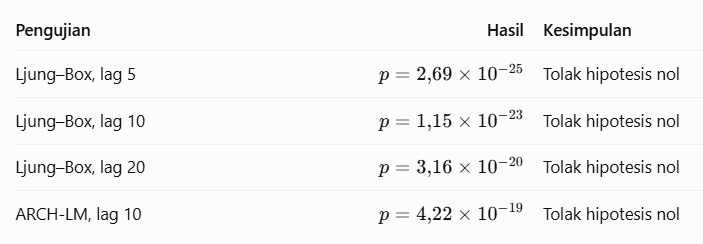

Karena seluruh p-value jauh di bawah 0,05, hasilnya signifikan secara statistik.
- Ljung–Box pada return kuadrat: terdapat autokorelasi pada return kuadrat hingga lag yang diuji. Artinya, besar fluktuasi return memiliki pola ketergantungan waktu.
- ARCH-LM: terdapat bukti efek ARCH, yaitu varians return berkaitan dengan informasi dari return masa lalu.

# Pembagian Data

In [ ]:

import pandas as pd
import numpy as np

# 1. Siapkan data return
# Menggunakan return yang sudah dihitung pada tahap EDA
dataset = returns.dropna().to_frame(name="Return").copy()
dataset = dataset.sort_index()

# 2. Tentukan batas pembagian data
n = len(dataset)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# 3. Split secara kronologis tanpa shuffle
train_data = dataset.iloc[:train_end].copy()
val_data = dataset.iloc[train_end:val_end].copy()
test_data = dataset.iloc[val_end:].copy()

# 4. Tampilkan jumlah dan rentang tanggal
hasil_split = pd.DataFrame({
    "Jumlah data": [
        len(train_data),
        len(val_data),
        len(test_data)
    ],
    "Proporsi aktual (%)": [
        len(train_data) / n * 100,
        len(val_data) / n * 100,
        len(test_data) / n * 100
    ],
    "Tanggal awal": [
        train_data.index.min().date(),
        val_data.index.min().date(),
        test_data.index.min().date()
    ],
    "Tanggal akhir": [
        train_data.index.max().date(),
        val_data.index.max().date(),
        test_data.index.max().date()
    ]
}, index=["Training", "Validation", "Testing"])

print("Total observasi:", n)
display(hasil_split)

# 5. Pastikan data tidak tumpang tindih
assert train_data.index.max() < val_data.index.min()
assert val_data.index.max() < test_data.index.min()

print("Split berhasil: urutan tanggal terjaga dan tidak tumpang tindih.")

Total observasi: 1198


,Jumlah data,Proporsi aktual (%),Tanggal awal,Tanggal akhir
Training,838,69.949917,2021-10-22,2025-04-17
Validation,180,15.025042,2025-04-21,2026-01-15
Testing,180,15.025042,2026-01-19,2026-10-20


Split berhasil: urutan tanggal terjaga dan tidak tumpang tindih.


# Data Augmentation pada Data Training


> Alasan pemilihan Moving Block Bootstrap (MBB)
1. Distribusi return tidak normal dan memiliki excess kurtosis tinggi.
2. Return kuadrat menunjukkan ketergantungan waktu.
3. MBB mempertahankan urutan observasi di dalam setiap blok, sehingga lebih sesuai untuk diuji dibandingkan mengacak setiap return secara independen.

membuat deret sintetis dengan mengambil blok-blok return berurutan dari data training, sehingga urutan di dalam setiap blok tetap terjaga.



,Data,Panjang blok,Mean,Std,Minimum,Maksimum,Skewness,Kurtosis
0,Training asli,-,0.000291,0.014147,-0.089153,0.057331,-0.153131,2.959364
1,MBB-5,5,0.000276,0.013838,-0.089153,0.045121,-0.036319,2.583716
2,MBB-10,10,0.000477,0.014101,-0.089153,0.057331,-0.196680,3.016464
3,MBB-20,20,0.000880,0.011359,-0.034887,0.042319,0.214913,0.897963


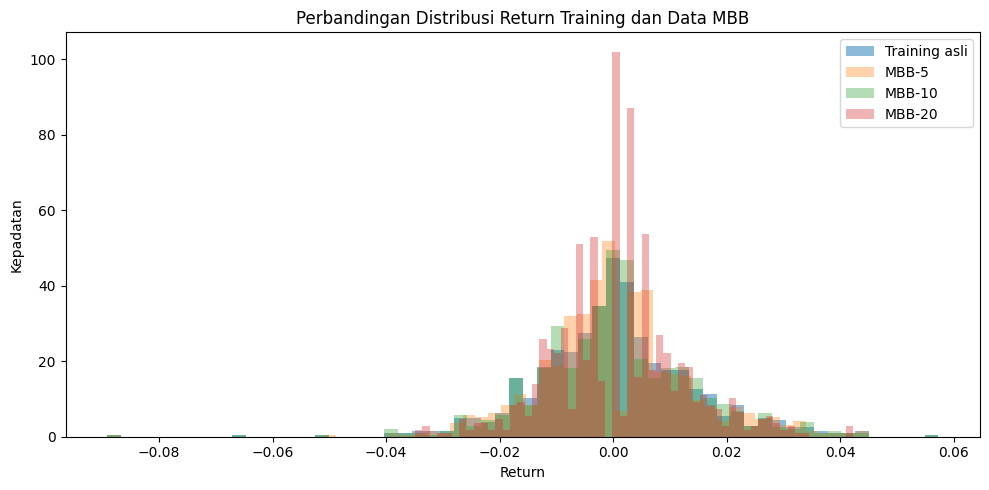

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan data training berupa satu kolom Return
train_returns = train_data["Return"].dropna().to_numpy()
n_train = len(train_returns)

def moving_block_bootstrap(data, block_length, random_state=42):
    """
    Menghasilkan deret sintetis dengan mengambil blok
    observasi berurutan dari data training.
    """
    rng = np.random.default_rng(random_state)
    n = len(data)

    if block_length < 1 or block_length > n:
        raise ValueError("Panjang blok harus antara 1 dan jumlah data training.")

    synthetic = []

    while len(synthetic) < n:
        # Pilih titik awal blok secara acak
        start = rng.integers(0, n - block_length + 1)

        # Ambil blok berurutan
        block = data[start:start + block_length]
        synthetic.extend(block)

    # Samakan panjang data sintetis dengan data training
    return np.asarray(synthetic[:n])


# Uji sensitivitas beberapa panjang blok
block_lengths = [5, 10, 20]
synthetic_train = {}

for block_length in block_lengths:
    synthetic_train[block_length] = moving_block_bootstrap(
        train_returns,
        block_length=block_length,
        random_state=42 + block_length
    )

# Bandingkan statistik data asli dan sintetis
hasil_mbb = [{
    "Data": "Training asli",
    "Panjang blok": "-",
    "Mean": np.mean(train_returns),
    "Std": np.std(train_returns, ddof=1),
    "Minimum": np.min(train_returns),
    "Maksimum": np.max(train_returns),
    "Skewness": pd.Series(train_returns).skew(),
    "Kurtosis": pd.Series(train_returns).kurt()
}]

for block_length, synthetic in synthetic_train.items():
    hasil_mbb.append({
        "Data": f"MBB-{block_length}",
        "Panjang blok": block_length,
        "Mean": np.mean(synthetic),
        "Std": np.std(synthetic, ddof=1),
        "Minimum": np.min(synthetic),
        "Maksimum": np.max(synthetic),
        "Skewness": pd.Series(synthetic).skew(),
        "Kurtosis": pd.Series(synthetic).kurt()
    })

hasil_mbb = pd.DataFrame(hasil_mbb)
display(hasil_mbb.round(6))

# Visualisasi perbandingan distribusi return
plt.figure(figsize=(10, 5))
plt.hist(train_returns, bins=60, alpha=0.5,
         density=True, label="Training asli")

for block_length, synthetic in synthetic_train.items():
    plt.hist(synthetic, bins=60, alpha=0.35,
             density=True, label=f"MBB-{block_length}")

plt.title("Perbandingan Distribusi Return Training dan Data MBB")
plt.xlabel("Return")
plt.ylabel("Kepadatan")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

# ============================================================
# 1. MEMBENTUK FITUR DAN TARGET
# ============================================================

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

# Pastikan return berbentuk Series dengan indeks tanggal
return_series = returns.dropna().sort_index().astype(float)

# Menggunakan 10 return terakhir sebagai fitur
N_LAGS = 10

def buat_supervised(series, n_lags=10):
    """
    Fitur berasal dari return hari ini dan sebelumnya.
    Target adalah return hari berikutnya.
    """
    values = np.asarray(series, dtype=float)
    dates = series.index

    X, y, target_dates = [], [], []

    for i in range(n_lags - 1, len(values) - 1):
        window = values[i - n_lags + 1:i + 1]

        fitur = list(window)
        fitur += [
            np.mean(window[-5:]),
            np.std(window[-5:], ddof=1),
            np.mean(window),
            np.std(window, ddof=1)
        ]

        X.append(fitur)
        y.append(values[i + 1])
        target_dates.append(dates[i + 1])

    kolom = (
        [f"Return_lag_{i}" for i in range(n_lags, 0, -1)]
        + ["Mean_5", "Std_5", "Mean_10", "Std_10"]
    )

    X = pd.DataFrame(X, columns=kolom, index=target_dates)
    y = pd.Series(y, index=target_dates, name="Target_Return")

    return X, y


X_all, y_all = buat_supervised(return_series, N_LAGS)

# Batas waktu mengikuti hasil split 70:15:15 sebelumnya
batas_train = train_data.index.max()
batas_val = val_data.index.max()
batas_test = test_data.index.max()

# Target dikelompokkan berdasarkan tanggal return yang diprediksi
mask_train = X_all.index <= batas_train
mask_val = (X_all.index > batas_train) & (X_all.index <= batas_val)
mask_test = (X_all.index > batas_val) & (X_all.index <= batas_test)

X_train = X_all.loc[mask_train]
y_train = y_all.loc[mask_train]

X_val = X_all.loc[mask_val]
y_val = y_all.loc[mask_val]

X_test = X_all.loc[mask_test]
y_test = y_all.loc[mask_test]

print("Jumlah sampel supervised:")
print("Training  :", len(X_train))
print("Validation:", len(X_val))
print("Testing   :", len(X_test))

print("\nPeriode target:")
print("Training  :", X_train.index.min().date(), "-", X_train.index.max().date())
print("Validation:", X_val.index.min().date(), "-", X_val.index.max().date())
print("Testing   :", X_test.index.min().date(), "-", X_test.index.max().date())

assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_test.index.min()

Jumlah sampel supervised:
Training  : 828
Validation: 180
Testing   : 180

Periode target:
Training  : 2021-11-05 - 2025-04-17
Validation: 2025-04-21 - 2026-01-15
Testing   : 2026-01-19 - 2026-10-20


In [ ]:

# ============================================================
# 2. MODEL ENSEMBLE REGRESI
# ============================================================

def buat_model():
    return {
        "Linear Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.03,
            max_depth=2,
            loss="huber",
            random_state=42
        )
    }


def evaluasi(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }


def latih_ensemble(X_fit, y_fit, X_eval):
    model_dict = buat_model()
    prediksi_individu = {}

    for nama, model in model_dict.items():
        model.fit(X_fit, y_fit)
        prediksi_individu[nama] = model.predict(X_eval)

    # Simple averaging: bobot setiap model sama
    prediksi_ensemble = np.mean(
        np.column_stack(list(prediksi_individu.values())),
        axis=1
    )

    return model_dict, prediksi_individu, prediksi_ensemble


# Baseline: tanpa augmentasi
model_baseline, pred_baseline_individu, pred_baseline_val = (
    latih_ensemble(X_train, y_train, X_val)
)

hasil_validasi = [{
    "Skenario": "Tanpa MBB",
    **evaluasi(y_val, pred_baseline_val)
}]

# Augmentasi MBB: uji beberapa panjang blok
hasil_model = {
    "Tanpa MBB": {
        "models": model_baseline,
        "val_prediction": pred_baseline_val
    }
}

train_returns = train_data["Return"].dropna().to_numpy()

for block_length in [5, 10, 20]:
    synthetic = moving_block_bootstrap(
        train_returns,
        block_length=block_length,
        random_state=42 + block_length
    )

    # Buat pasangan fitur-target dari urutan sintetis
    synthetic_series = pd.Series(synthetic)
    X_syn, y_syn = buat_supervised(synthetic_series, N_LAGS)

    # Gabungkan sampel asli dengan sampel sintetis
    X_aug = np.vstack([X_train.to_numpy(), X_syn.to_numpy()])
    y_aug = np.concatenate([y_train.to_numpy(), y_syn.to_numpy()])

    model_aug, pred_individu, pred_val = latih_ensemble(
        X_aug, y_aug, X_val
    )

    nama_skenario = f"MBB-{block_length}"

    hasil_validasi.append({
        "Skenario": nama_skenario,
        **evaluasi(y_val, pred_val)
    })

    hasil_model[nama_skenario] = {
        "models": model_aug,
        "val_prediction": pred_val
    }

# Bandingkan hasil validation
tabel_validasi = pd.DataFrame(hasil_validasi)
tabel_validasi = tabel_validasi.sort_values("RMSE")

display(tabel_validasi.round(8))

# Pilih skenario dengan RMSE validation terendah
skenario_terbaik = tabel_validasi.iloc[0]["Skenario"]
print("Skenario terpilih:", skenario_terbaik)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X h

,Skenario,MAE,RMSE
1,MBB-5,0.011812,0.015772
3,MBB-20,0.011876,0.015786
0,Tanpa MBB,0.012001,0.015928
2,MBB-10,0.012097,0.016109


Skenario terpilih: MBB-5


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(


,Model,MAE,RMSE
2,Gradient Boosting,0.017463,0.026166
3,Ensemble,0.017738,0.026543
1,Random Forest,0.018177,0.026756
0,Linear Regression,0.018035,0.027065


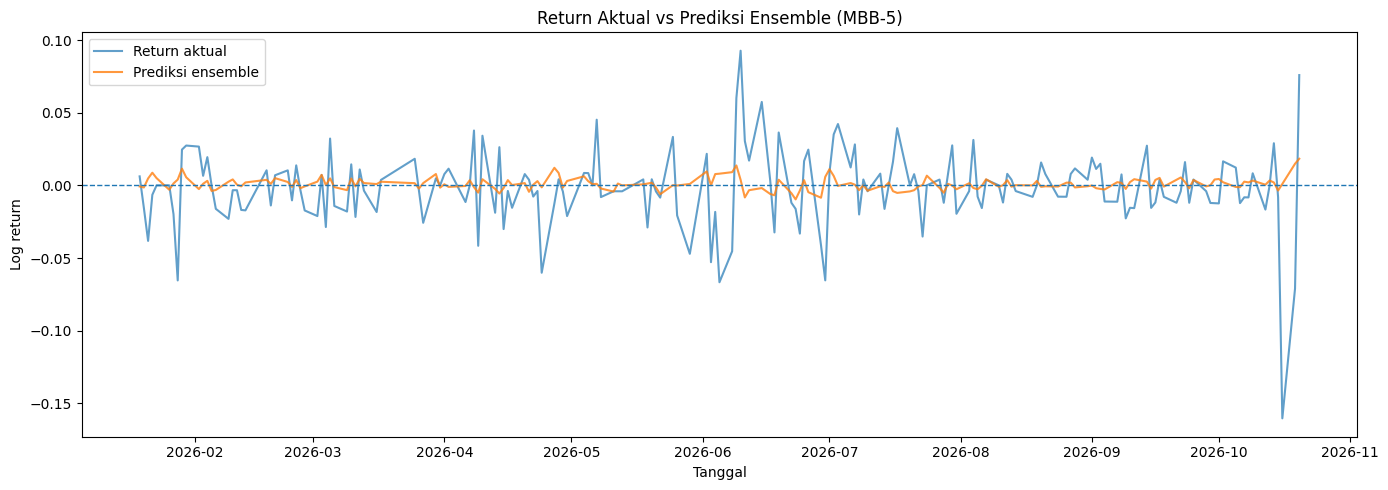

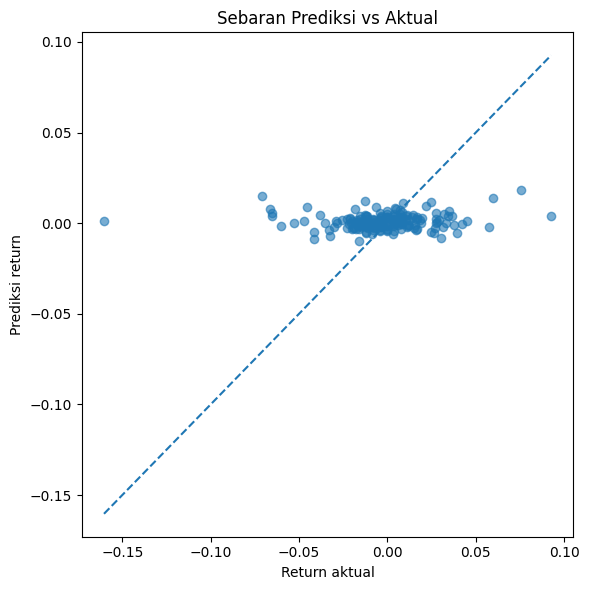

In [ ]:

# ============================================================
# 3. EVALUASI FINAL PADA TESTING
# ============================================================

# Model skenario terpilih sudah dilatih menggunakan training
# dan (jika MBB) data sintetis training.
models_final = hasil_model[skenario_terbaik]["models"]

pred_test_individu = {}
for nama, model in models_final.items():
    pred_test_individu[nama] = model.predict(X_test)

pred_test_ensemble = np.mean(
    np.column_stack(list(pred_test_individu.values())),
    axis=1
)

# Prediksi model terbaik dibandingkan model individu
hasil_testing = []

for nama, pred in pred_test_individu.items():
    hasil_testing.append({
        "Model": nama,
        **evaluasi(y_test, pred)
    })

hasil_testing.append({
    "Model": "Ensemble",
    **evaluasi(y_test, pred_test_ensemble)
})

tabel_testing = pd.DataFrame(hasil_testing).sort_values("RMSE")
display(tabel_testing.round(8))

# Grafik return aktual dan prediksi ensemble
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test.values,
         label="Return aktual", alpha=0.7)
plt.plot(y_test.index, pred_test_ensemble,
         label="Prediksi ensemble", alpha=0.8)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title(f"Return Aktual vs Prediksi Ensemble ({skenario_terbaik})")
plt.xlabel("Tanggal")
plt.ylabel("Log return")
plt.legend()
plt.tight_layout()
plt.show()

# Plot sebaran prediksi terhadap nilai aktual
plt.figure(figsize=(6, 6))
plt.scatter(y_test.values, pred_test_ensemble, alpha=0.6)
batas_min = min(y_test.min(), pred_test_ensemble.min())
batas_max = max(y_test.max(), pred_test_ensemble.max())
plt.plot([batas_min, batas_max], [batas_min, batas_max],
         linestyle="--")
plt.xlabel("Return aktual")
plt.ylabel("Prediksi return")
plt.title("Sebaran Prediksi vs Aktual")
plt.tight_layout()
plt.show()

,Strategi,Total Return (%),Sharpe Ratio,Max Drawdown (%),Turnover
0,Prediksi Ensemble (Long/Cash),-25.9796,-0.9877,-31.3888,85
1,Buy-and-Hold,-32.3757,-1.1078,-37.6946,85


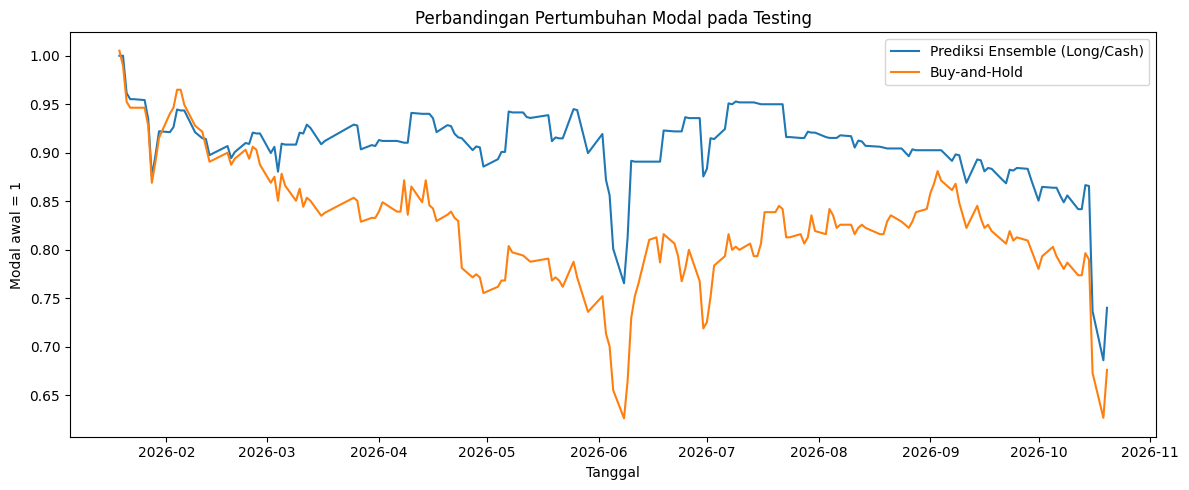

In [ ]:

# ============================================================
# 4. BACKTEST BASELINE STRATEGI
# ============================================================

# Prediksi return adalah log return.
# Ubah return aktual menjadi simple return untuk simulasi kekayaan.
actual_simple = np.expm1(y_test.to_numpy())

# Strategi long/cash:
# 1 = memegang saham, 0 = kas
position = (pred_test_ensemble > 0).astype(int)

# Biaya transaksi asumsi 0,1% dari nilai transaksi
transaction_cost = 0.001

# Turnover = perubahan posisi; posisi awal diasumsikan kas
previous_position = np.r_[0, position[:-1]]
turnover = np.abs(position - previous_position)

strategy_returns = (
    position * actual_simple
    - turnover * transaction_cost
)

# Buy-and-Hold: membeli pada awal periode testing
buy_hold_position = np.ones(len(actual_simple))
buy_hold_previous = np.r_[0, buy_hold_position[:-1]]
buy_hold_turnover = np.abs(buy_hold_position - buy_hold_previous)

buy_hold_returns = (
    buy_hold_position * actual_simple
    - buy_hold_turnover * transaction_cost
)


def metrik_trading(daily_returns):
    daily_returns = np.asarray(daily_returns, dtype=float)
    wealth = np.cumprod(1 + daily_returns)

    total_return = wealth[-1] - 1
    daily_std = np.std(daily_returns, ddof=1)

    sharpe = (
        np.mean(daily_returns) / daily_std * np.sqrt(252)
        if daily_std > 0 else np.nan
    )

    running_peak = np.maximum.accumulate(np.r_[1, wealth])[1:]
    drawdown = wealth / running_peak - 1
    max_drawdown = np.min(drawdown)

    return {
        "Total Return (%)": total_return * 100,
        "Sharpe Ratio": sharpe,
        "Max Drawdown (%)": max_drawdown * 100,
        "Turnover": np.sum(turnover)
    }


hasil_strategi = pd.DataFrame([
    {
        "Strategi": "Prediksi Ensemble (Long/Cash)",
        **metrik_trading(strategy_returns)
    },
    {
        "Strategi": "Buy-and-Hold",
        **metrik_trading(buy_hold_returns)
    }
])

display(hasil_strategi.round(4))

# Grafik pertumbuhan modal
wealth_strategy = np.cumprod(1 + strategy_returns)
wealth_buy_hold = np.cumprod(1 + buy_hold_returns)

plt.figure(figsize=(12, 5))
plt.plot(y_test.index, wealth_strategy,
         label="Prediksi Ensemble (Long/Cash)")
plt.plot(y_test.index, wealth_buy_hold,
         label="Buy-and-Hold")
plt.title("Perbandingan Pertumbuhan Modal pada Testing")
plt.xlabel("Tanggal")
plt.ylabel("Modal awal = 1")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

# ============================================================
# LANGKAH 6A. PREDIKSI ENSEMBLE WALK-FORWARD UNTUK RL
# ============================================================

from sklearn.model_selection import TimeSeriesSplit

# Tentukan panjang blok dari skenario validation terbaik
if skenario_terbaik == "Tanpa MBB":
    rl_block_length = None
else:
    rl_block_length = int(skenario_terbaik.split("-")[1])

N_SPLITS = 5

# Menampung prediksi out-of-fold pada data training
oof_prediction = np.full(len(X_train), np.nan)

tscv = TimeSeriesSplit(n_splits=N_SPLITS)

for fold, (idx_fit, idx_oof) in enumerate(tscv.split(X_train), start=1):

    X_fit = X_train.iloc[idx_fit]
    y_fit = y_train.iloc[idx_fit]
    X_oof = X_train.iloc[idx_oof]

    # Augmentasi hanya dari data training fold
    if rl_block_length is not None:
        synthetic = moving_block_bootstrap(
            y_fit.to_numpy(),
            block_length=rl_block_length,
            random_state=1000 + fold
        )

        X_syn, y_syn = buat_supervised(
            pd.Series(synthetic),
            N_LAGS
        )

        X_fit_final = np.vstack([
            X_fit.to_numpy(),
            X_syn.to_numpy()
        ])

        y_fit_final = np.concatenate([
            y_fit.to_numpy(),
            y_syn.to_numpy()
        ])
    else:
        X_fit_final = X_fit
        y_fit_final = y_fit

    # Latih ketiga model hanya pada data sebelum fold OOF
    _, _, pred_fold = latih_ensemble(
        X_fit_final,
        y_fit_final,
        X_oof
    )

    oof_prediction[idx_oof] = pred_fold

    print(
        f"Fold {fold}: "
        f"fit={len(idx_fit)}, "
        f"OOF={len(idx_oof)}"
    )

# Ambil observasi yang memiliki prediksi OOF
mask_oof = np.isfinite(oof_prediction)

X_rl_train = X_train.iloc[np.where(mask_oof)[0]].copy()
y_rl_train = y_train.iloc[np.where(mask_oof)[0]].copy()
pred_rl_train = oof_prediction[mask_oof]

print("\nJumlah data untuk pelatihan RL:", len(X_rl_train))
print("Jumlah prediksi OOF valid:", len(pred_rl_train))

assert len(X_rl_train) > 0
assert np.isfinite(pred_rl_train).all()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Fold 1: fit=138, OOF=138


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Fold 2: fit=276, OOF=138


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Fold 4: fit=552, OOF=138


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


Fold 5: fit=690, OOF=138

Jumlah data untuk pelatihan RL: 690
Jumlah prediksi OOF valid: 690


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(


In [ ]:

# ============================================================
# LANGKAH 6B. MENYIAPKAN STATE RL
# ============================================================

from sklearn.preprocessing import StandardScaler

# Prediksi validation dan testing dari ensemble terpilih
pred_rl_val = models_final and np.mean(
    np.column_stack([
        model.predict(X_val)
        for model in models_final.values()
    ]),
    axis=1
)

pred_rl_test = np.mean(
    np.column_stack([
        model.predict(X_test)
        for model in models_final.values()
    ]),
    axis=1
)

# Standardisasi hanya menggunakan prediksi OOF training
fitur_train_rl = np.column_stack([
    X_rl_train.to_numpy(),
    pred_rl_train
])

scaler_rl = StandardScaler()
Z_train = scaler_rl.fit_transform(fitur_train_rl)


def bentuk_state(X, pred, posisi, scaler):
    fitur = np.column_stack([
        X.to_numpy(),
        np.asarray(pred)
    ])

    fitur_scaled = scaler.transform(fitur)

    # Posisi ditambahkan setelah standardisasi:
    # 0 = kas, 1 = saham
    return np.column_stack([
        fitur_scaled,
        np.asarray(posisi).reshape(-1)
    ]).astype(np.float32)


# Posisi awal untuk setiap episode adalah kas
posisi_awal_train = np.zeros(len(X_rl_train))

state_train = bentuk_state(
    X_rl_train,
    pred_rl_train,
    posisi_awal_train,
    scaler_rl
)

return_train_simple = np.expm1(y_rl_train.to_numpy())

print("Dimensi state:", state_train.shape)
print("Jumlah fitur state:", state_train.shape[1])

Dimensi state: (690, 16)
Jumlah fitur state: 16


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X h

In [ ]:

# ============================================================
# LANGKAH 6C. DQN AGENT
# ============================================================

import random
from collections import deque

import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Aksi:
# 0 = Buy  -> posisi menjadi 1
# 1 = Hold -> posisi tetap
# 2 = Sell -> posisi menjadi 0

def posisi_setelah_aksi(aksi, posisi):
    if aksi == 0:
        return 1
    elif aksi == 2:
        return 0
    return posisi


class DQN(nn.Module):
    def __init__(self, input_dim, n_actions=3):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, n_actions)
        )

    def forward(self, x):
        return self.net(x)


class ReplayBuffer:
    def __init__(self, capacity=20000):
        self.memory = deque(maxlen=capacity)

    def add(self, transition):
        self.memory.append(transition)

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)


input_dim = state_train.shape[1]

policy_net = DQN(input_dim).to(device)
target_net = DQN(input_dim).to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

replay_buffer = ReplayBuffer()

GAMMA = 0.99
BATCH_SIZE = 64
N_EPISODES = 300
TRANSACTION_COST = 0.001

epsilon_start = 1.0
epsilon_end = 0.05
epsilon_decay = 0.99


def pilih_aksi(state, epsilon):
    if random.random() < epsilon:
        return random.randrange(3)

    with torch.no_grad():
        s = torch.tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        return int(policy_net(s).argmax(dim=1).item())


def update_dqn():
    if len(replay_buffer) < BATCH_SIZE:
        return

    batch = replay_buffer.sample(BATCH_SIZE)

    states = torch.tensor(
        np.array([x[0] for x in batch]),
        dtype=torch.float32, device=device
    )
    actions = torch.tensor(
        [x[1] for x in batch],
        dtype=torch.int64, device=device
    ).unsqueeze(1)
    rewards = torch.tensor(
        [x[2] for x in batch],
        dtype=torch.float32, device=device
    )
    next_states = torch.tensor(
        np.array([x[3] for x in batch]),
        dtype=torch.float32, device=device
    )
    dones = torch.tensor(
        [x[4] for x in batch],
        dtype=torch.float32, device=device
    )

    q_values = policy_net(states).gather(1, actions).squeeze(1)

    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1).values
        target = rewards + GAMMA * next_q * (1 - dones)

    loss = nn.functional.smooth_l1_loss(q_values, target)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        policy_net.parameters(), max_norm=1.0
    )
    optimizer.step()


# ============================================================
# PELATIHAN DQN PADA DATA TRAINING OOF
# ============================================================

epsilon = epsilon_start
riwayat_reward = []

for episode in range(N_EPISODES):
    posisi = 0
    total_reward = 0.0

    for t in range(len(state_train)):
        state = state_train[t].copy()

        aksi = pilih_aksi(state, epsilon)
        posisi_baru = posisi_setelah_aksi(aksi, posisi)

        # Return pada tanggal target yang sesuai dengan state
        ret = return_train_simple[t]

        # Biaya hanya saat posisi berubah
        turnover = abs(posisi_baru - posisi)

        reward = (
            posisi_baru * ret
            - TRANSACTION_COST * turnover
        )

        # Skala reward agar optimisasi lebih stabil
        reward_scaled = reward * 100

        done = (t == len(state_train) - 1)

        if not done:
            next_state = state_train[t + 1].copy()
            next_state[-1] = posisi_baru
        else:
            next_state = state.copy()
            next_state[-1] = posisi_baru

        replay_buffer.add((
            state,
            aksi,
            reward_scaled,
            next_state,
            float(done)
        ))

        update_dqn()

        posisi = posisi_baru
        total_reward += reward

        if done:
            break

    epsilon = max(epsilon_end, epsilon * epsilon_decay)

    if (episode + 1) % 10 == 0:
        target_net.load_state_dict(policy_net.state_dict())

    riwayat_reward.append(total_reward)

    if (episode + 1) % 50 == 0:
        print(
            f"Episode {episode + 1:3d} | "
            f"Reward: {total_reward:.5f} | "
            f"Epsilon: {epsilon:.3f}"
        )

print("\nPelatihan DQN selesai.")

Episode  50 | Reward: 0.68412 | Epsilon: 0.605
Episode 100 | Reward: 1.54165 | Epsilon: 0.366
Episode 150 | Reward: 2.24971 | Epsilon: 0.221
Episode 200 | Reward: 2.19110 | Epsilon: 0.134
Episode 250 | Reward: 2.53934 | Epsilon: 0.081
Episode 300 | Reward: 2.44867 | Epsilon: 0.050

Pelatihan DQN selesai.


HASIL VALIDATION


,Strategi,Total Return (%),Sharpe Ratio,Max Drawdown (%),Total Turnover,Jumlah Buy
0,DQN,-19.1445,-1.9976,-21.1488,60.0,0.0
1,Buy-and-Hold,-4.4699,-0.1285,-25.2577,1.0,0.0


HASIL TESTING FINAL


,Strategi,Total Return (%),Sharpe Ratio,Max Drawdown (%),Total Turnover,Jumlah Buy
0,DQN,-24.7701,-0.9869,-31.1024,83.0,0.0
1,Buy-and-Hold,-32.3757,-1.1078,-37.6946,1.0,0.0


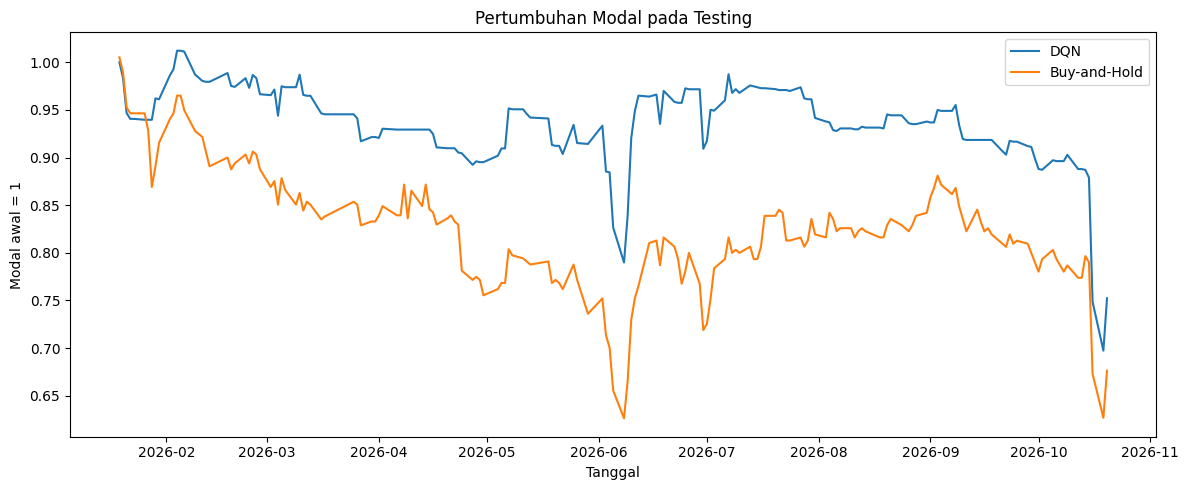

Distribusi aksi DQN pada testing:


,Jumlah
Aksi,
Buy,99
Sell,77
Hold,4


In [ ]:

# ============================================================
# LANGKAH 6D. EVALUASI KEBIJAKAN DQN
# ============================================================

def evaluasi_dqn(X, y, pred, scaler, model, biaya=0.001):
    posisi = 0
    actions = []
    positions = []
    daily_returns = []
    turnovers = []

    actual_simple = np.expm1(y.to_numpy())

    # Proses kronologis: posisi sebelumnya masuk ke state
    for t in range(len(X)):
        state = bentuk_state(
            X.iloc[[t]],
            [pred[t]],
            [posisi],
            scaler
        )[0]

        with torch.no_grad():
            s = torch.tensor(
                state, dtype=torch.float32, device=device
            ).unsqueeze(0)

            action = int(model(s).argmax(dim=1).item())

        new_position = posisi_setelah_aksi(action, posisi)
        turnover = abs(new_position - posisi)

        net_return = (
            new_position * actual_simple[t]
            - biaya * turnover
        )

        actions.append(action)
        positions.append(new_position)
        turnovers.append(turnover)
        daily_returns.append(net_return)

        posisi = new_position

    return {
        "actions": np.asarray(actions),
        "positions": np.asarray(positions),
        "returns": np.asarray(daily_returns),
        "turnover": np.asarray(turnovers)
    }


def hitung_metrik(daily_returns, turnovers):
    r = np.asarray(daily_returns, dtype=float)
    wealth = np.cumprod(1 + r)

    if len(r) == 0:
        return {}

    total_return = wealth[-1] - 1
    daily_std = np.std(r, ddof=1) if len(r) > 1 else 0.0

    sharpe = (
        np.mean(r) / daily_std * np.sqrt(252)
        if daily_std > 0 else np.nan
    )

    running_peak = np.maximum.accumulate(
        np.r_[1.0, wealth]
    )[1:]

    drawdown = wealth / running_peak - 1

    return {
        "Total Return (%)": 100 * total_return,
        "Sharpe Ratio": sharpe,
        "Max Drawdown (%)": 100 * np.min(drawdown),
        "Total Turnover": np.sum(turnovers),
        "Jumlah Buy": np.sum(np.asarray(
            # Aksi Buy ketika sebelumnya bukan saham
            []
        ))
    }


# Prediksi validation/testing dibuat oleh ensemble final
hasil_val_rl = evaluasi_dqn(
    X_val, y_val, pred_rl_val, scaler_rl, policy_net
)

hasil_test_rl = evaluasi_dqn(
    X_test, y_test, pred_rl_test, scaler_rl, policy_net
)

# Buy-and-Hold sebagai pembanding pada setiap periode
def hasil_buy_hold(y, biaya=0.001):
    r = np.expm1(y.to_numpy())
    turnover = np.zeros(len(r))

    if len(r) > 0:
        turnover[0] = 1  # Membeli pada awal periode

    net = r - biaya * turnover
    return net, turnover


val_bh, val_bh_turnover = hasil_buy_hold(y_val)
test_bh, test_bh_turnover = hasil_buy_hold(y_test)

tabel_val_rl = pd.DataFrame([
    {
        "Strategi": "DQN",
        **hitung_metrik(
            hasil_val_rl["returns"],
            hasil_val_rl["turnover"]
        )
    },
    {
        "Strategi": "Buy-and-Hold",
        **hitung_metrik(val_bh, val_bh_turnover)
    }
])

tabel_test_rl = pd.DataFrame([
    {
        "Strategi": "DQN",
        **hitung_metrik(
            hasil_test_rl["returns"],
            hasil_test_rl["turnover"]
        )
    },
    {
        "Strategi": "Buy-and-Hold",
        **hitung_metrik(test_bh, test_bh_turnover)
    }
])

print("HASIL VALIDATION")
display(tabel_val_rl.round(4))

print("HASIL TESTING FINAL")
display(tabel_test_rl.round(4))


# Grafik pertumbuhan modal pada testing
wealth_dqn = np.cumprod(1 + hasil_test_rl["returns"])
wealth_bh = np.cumprod(1 + test_bh)

plt.figure(figsize=(12, 5))
plt.plot(y_test.index, wealth_dqn, label="DQN")
plt.plot(y_test.index, wealth_bh, label="Buy-and-Hold")
plt.title("Pertumbuhan Modal pada Testing")
plt.xlabel("Tanggal")
plt.ylabel("Modal awal = 1")
plt.legend()
plt.tight_layout()
plt.show()

# Distribusi aksi DQN
nama_aksi = {0: "Buy", 1: "Hold", 2: "Sell"}
aksi_test = pd.Series(hasil_test_rl["actions"]).map(nama_aksi)

print("Distribusi aksi DQN pada testing:")
display(aksi_test.value_counts().rename_axis("Aksi").to_frame("Jumlah"))